## import required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    balanced_accuracy_score
)

---
## 2. load the dataset

In [20]:
df = pd.read_csv('heart.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())



Dataset Shape: (270, 5)

First 5 rows:
   age  sex   BP  cholestrol  heart_disease
0   70    1  130         322              1
1   67    0  115         564              0
2   57    1  124         261              1
3   64    1  128         263              0
4   74    0  120         269              0


---
# Part A:
1. Train a Decision Tree classifier on the Heart Disease dataset.
2. training and testing accuracy.
3. Visualize the decision tree and interpret the first two splits.

In [22]:
# splitting 
X = df[['age', 'sex', 'BP', 'cholestrol']]
y = df['heart_disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=43
)

dt_model = DecisionTreeClassifier(random_state=43)
dt_model.fit(X_train, y_train)
depth = dt_model.get_depth()
print(depth)
    
y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_acc:.2f}")
print(f"Testing Accuracy:  {test_acc:.2f}")

14
Training Accuracy: 1.00
Testing Accuracy:  0.70


### Tree Visualization

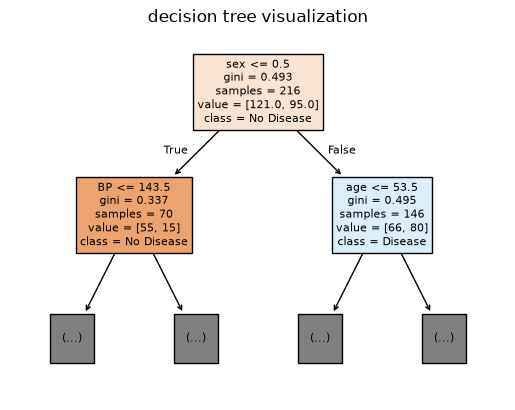

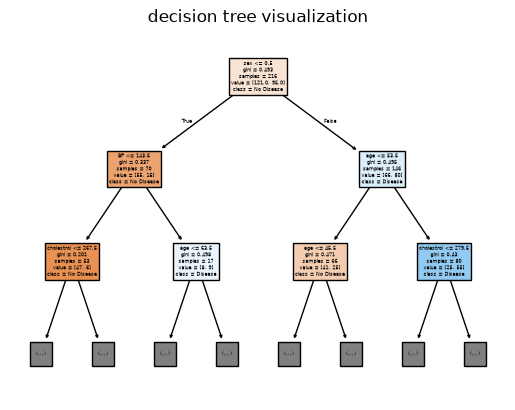

In [5]:
plot_tree(
    dt_model,
    max_depth=1,
    feature_names=X.columns,
    class_names=['No Disease', 'Disease'],
    filled=True
)
plt.title("decision tree visualization")
plt.show()
plot_tree(
    dt_model,
    max_depth=2,
    feature_names=X.columns,
    class_names=['No Disease', 'Disease'],
    filled=True
)
plt.title("decision tree visualization")
plt.show()

- gini impurity is basically used to analyze how mixed up of classes a node is.
- for two classes max gini is 0.5 because 50/50 split
- formula is 1 - sum(Pi^2) where Pi is a proportion sample aka how much of a class does

#### **Interpretation of the First Two Splits:**
1. **Root Node (First Split):**
   - Select the feature that give greatest reduction in Gini impurity.
   - For example, if the root split tests `cholestrol <= 244.5`, patients with cholesterol $\le 244.5$ go to the left branch, while those with $> 244.5$ go to the right branch.
2. **Second Level Nodes (Second Splits):**
   - The child nodes partition further using secondary attributes like `age`, `sex`, or `BP`.
   - For example, within the lower cholesterol subset, the tree tests `age <= 55.5` or `sex <= 0.5` to separate lower-risk and higher-risk patients.

---
# Part B: Model Evaluation

1. Print the Confusion Matrix and Classification Report (Precision, Recall, F1-Score).
2. Plot the ROC Curve and report the AUC score.

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix:")
print("\t\t pred no  pred yes \n actual no\t(TN)\t\t(FP) \n actual yes\t (FN)\t\t (TP)")
print(cm)

report = classification_report(
    y_test,
    y_test_pred,
    target_names=['No Disease', 'Disease'],
    output_dict=True
)

report_df = pd.DataFrame(report).T
report_df = report_df.drop(['macro avg', 'weighted avg'])
report_df = report_df.drop(columns=['support'])

print(report_df)

Confusion Matrix:
		 pred no  pred yes 
 actual no	(TN)		(FP) 
 actual yes	 (FN)		 (TP)
[[22  7]
 [ 9 16]]
            precision    recall  f1-score
No Disease   0.709677  0.758621  0.733333
Disease      0.695652  0.640000  0.666667
accuracy     0.703704  0.703704  0.703704


- for precision = TP/TP + FP = 17/17+15 = 0.53 (for disease) all the people who actually have a disease out of predicted
- recall: of all the people who have disease how many did model predict   TP/TP+FN
- f1: combination of precision and recall: f1 = 2 * (p * r) / (p + r). the overall balance of the model between p and r
- model is 62% accurate overall. It detects 61% of actual disease cases, but when it predicts Disease, it is correct only 53% of the time.

ROC-AUC Score: 0.70
Receiver Operating Characteristic


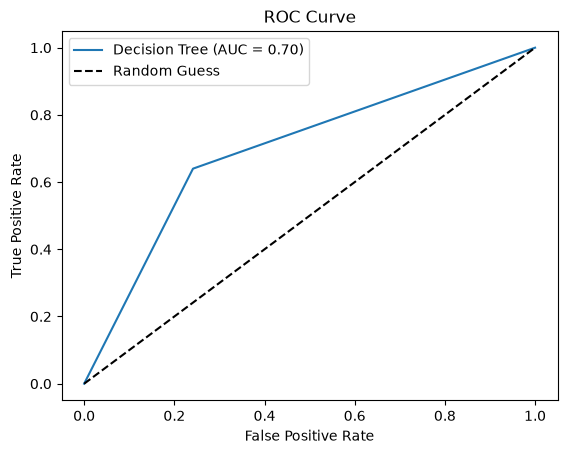

In [24]:
# Predict probabilities for the positive class (Heart Disease = 1)
y_test_prob = dt_model.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC score
# false +ve, true +ve
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

auc_score = roc_auc_score(y_test, y_test_prob)

print(f"ROC-AUC Score: {auc_score:.2f}")
print("Receiver Operating Characteristic")

plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

- AUC - how well a classification model differentiates between positive and negative classes
- ROC(Receiver Operating Characteristic) - how well a model performs across different threshold values

- 1 is perfect AUC
- 0.5 is random guessing
- 0.70 is decent

---
# Part C: Hyperparameter Tuning

1. Vary `max_depth`, `min_samples_split`, `min_samples_leaf` to observe overfitting vs underfitting.
2. Plot training vs testing accuracy across depths.
3. Use `GridSearchCV` for automated hyperparameter tuning.

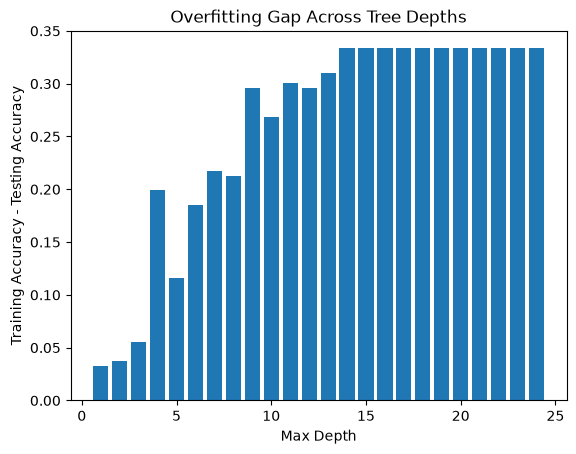

In [8]:
# Analyze Effect of max_depth on Overfitting vs Underfitting
depths = range(1, 25)
train_scores = []
test_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    train_scores.append(clf.score(X_train, y_train))
    test_scores.append(clf.score(X_test, y_test))

accuracy_gap = [train - test for train, test in zip(train_scores, test_scores)]

plt.bar(depths, accuracy_gap)
plt.xlabel("Max Depth")
plt.ylabel("Training Accuracy - Testing Accuracy")
plt.title("Overfitting Gap Across Tree Depths")
plt.show()

#### **Observation on Overfitting vs Underfitting:**
- **Underfitting (Low depth, max_depth = 1 or 2):** Both training and testing accuracy are relatively low because the tree is very simple.
- **Overfitting (High depth, max_depth > 5):** Training accuracy reaches 100%, but testing accuracy drops or plateaus because tree learns too much.
- **Optimal Balance:** A restricted depth (e.g. `max_depth = 3`) prevents overfitting and improves generalization on unseen test data.

In [9]:
# Automated Hyperparameter Tuning using GridSearchCV
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8],
    'min_samples_split': [2, 5, 10, 15], # min samples needed to split a node
    'min_samples_leaf': [1, 2, 4, 8], # min samples that should be left in a leaf
    'criterion': ['gini', 'entropy']    # method used to measure quality
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=43),
    param_grid,
    cv=5,
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print(f"Best CV Accuracy: {grid_search.best_score_:.2f}")

# Evaluate Tuned Model on Test Set
best_model = grid_search.best_estimator_
best_test_acc = best_model.score(X_test, y_test)
print(f"Tuned Model Test Accuracy: {best_test_acc:.2f}")

Best Parameters: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best CV Accuracy: 0.68
Tuned Model Test Accuracy: 0.70


---
# Part D: Error Analysis

1. Find the patients (rows) that were misclassified by the decision tree.
2. Compare their features with correctly classified patients.
3. What patterns do you notice?

In [10]:
test_results = X_test.copy() # copy of testt data
test_results['Actual'] = y_test
test_results['Predicted'] = y_test_pred
test_results['Correct'] = test_results['Actual'] == test_results['Predicted']

# Misclassified vs Correctly Classified
misclassified = test_results[~test_results['Correct']]
correct = test_results[test_results['Correct']]

print(f"Total Test Samples: {len(test_results)}")
print(f"Misclassified Count: {len(misclassified)}")
print("\n Some Misclassified Instances:")
print(misclassified.head())

Total Test Samples: 54
Misclassified Count: 16

 Some Misclassified Instances:
     age  sex   BP  cholestrol  Actual  Predicted  Correct
235   62    0  160         164       1          0    False
158   56    1  120         193       0          1    False
130   63    0  108         269       1          0    False
38    42    1  130         180       0          1    False
159   66    0  178         228       1          0    False


#### **Patterns in Misclassified Patients:**
   - Younger patients with high cholesterol or older patients with normal cholesterol/BP are often misclassified because the decision tree relies heavily on general cutoff rules.
   - borderline values can go in opposite direction

---
# Part E: Class Imbalance Check

1. Check target class distribution (Heart Disease = 1 vs No Disease = 0).
2. Evaluate Balanced Accuracy and test class-weighted training.

Class Distribution:
heart_disease
0    150
1    120
Name: count, dtype: int64

Percentage Distribution:
heart_disease
0    55.555556
1    44.444444
Name: proportion, dtype: float64


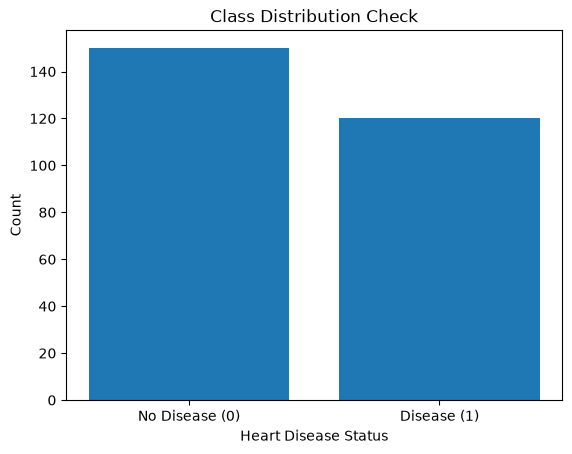

In [18]:
# Check class distribution
class_counts = df['heart_disease'].value_counts()
print("Class Distribution:")
print(class_counts)
print("\nPercentage Distribution:")
print(df['heart_disease'].value_counts(normalize=True) * 100)

# Plot class balance
plt.bar(['No Disease (0)', 'Disease (1)'], class_counts.values)
plt.xlabel("Heart Disease Status")
plt.ylabel("Count")
plt.title("Class Distribution Check")
plt.show()

In [ ]:
balanced_acc = balanced_accuracy_score(y_test, y_test_pred)
print(f"Standard Accuracy: {test_acc:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")


Standard Accuracy: 0.7037
Balanced Accuracy: 0.6993


#### **Conclusion for Part E:**
- **Class Balance Analysis:** The dataset has **150 patients without disease (55.6%)** and **120 patients with disease (44.4%)**.
- **Observation:** The dataset is moderately balanced without extreme skew.
- **Recommendations:** Using `balanced_accuracy_score` and `class_weight='balanced'` ensures that both sensitivity (true positive rate) and specificity (true negative rate) are evenly weighted.